## Datenhandling mit PANDAS

Um Daten besser und einfacher handhaben zu können - insbesondere für die Analyse - bietet sich die Verwendung der Programmbibliothek **Pandas** an.

Beispiel: Einlesen einer CSV-Datei mit einer Liste von Videospielen mit mehr als 100.000 verkauften Exemplaren (Quelle: [kaggle](https://www.kaggle.com/datasets/gregorut/videogamesales)).  Die Verkaufszahlen sind in Millionen Stück angegeben. 



In [1]:
import pandas as pd

videogames_df = pd.read_csv("vgsales.csv")
videogames_df


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


Selektion eines neuen Datenrahmens mit den  Spalten „Rank„, „Name“, „Platform“, „Genre“ und „Global_Sales".

In [2]:
to_db = videogames_df[['Rank', 'Name', 'Platform', 'Genre', 'Global_Sales']]

In [3]:
to_db

,Rank,Name,Platform,Genre,Global_Sales
0,1,Wii Sports,Wii,Sports,82.74
1,2,Super Mario Bros.,NES,Platform,40.24
2,3,Mario Kart Wii,Wii,Racing,35.82
3,4,Wii Sports Resort,Wii,Sports,33.00
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,31.37
...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,Platform,0.01
16594,16597,Men in Black II: Alien Escape,GC,Shooter,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,Racing,0.01
16596,16599,Know How 2,DS,Puzzle,0.01


Speichern dieses Datenrahmens als neue Tabelle:

In [4]:
import sqlite3

# connect to SQLite database
con = sqlite3.connect('example.db')

to_db.to_sql('Videogame_Sales',con=con,if_exists='replace',index=False)

con.commit()
con.close()

Die volle Funktionalität und [API](https://pandas.pydata.org/docs/reference/index.html#api) von Pandas ist gut [dokumentiert](https://pandas.pydata.org/docs/index.html). Und sonst kann auch ChatGPT weiterhelfen...

Zum Beispiel hier zum Einlesen einer Tabelle aus der Datenbank:

In [5]:
# Initial Code generated with ChatGPT using the following prompt:
# write python code using the pandas library that reads the table named 'Mitarbeiter' from a SQLite database called 'example.db' into a data frame and then loops through all the rows of the data frame.

import pandas as pd
import sqlite3

# connect to SQLite database
conn = sqlite3.connect('example.db')

# read the 'Mitarbeiter' table into a pandas DataFrame
df = pd.read_sql_query("SELECT * from Mitarbeiter", conn)

# loop through all rows in the DataFrame
for index, row in df.iterrows():
    print(row['id'], row['name'], row['lohn']) # replace 'column_name' with the name of the column you want to print
    
conn.close()

1 Anja 10000.0
2 Flurina 7000.0
3 Michael 50000.0
4 Amir 9000.0
5 Maria 3000.0
6 Urs 10000.0
7 Kathrin 6000.0
10 Annika 5000.0
11 Regula 4000.0
12 Roger 15000.0
13 Meyrem 8000.0
14 Alice 9500.0
15 Bob 13000.0
16 Claudia 12500.0


Pandas macht es auch einfach, Grafiken zu generieren:

Index(['name', 'lohn'], dtype='object')


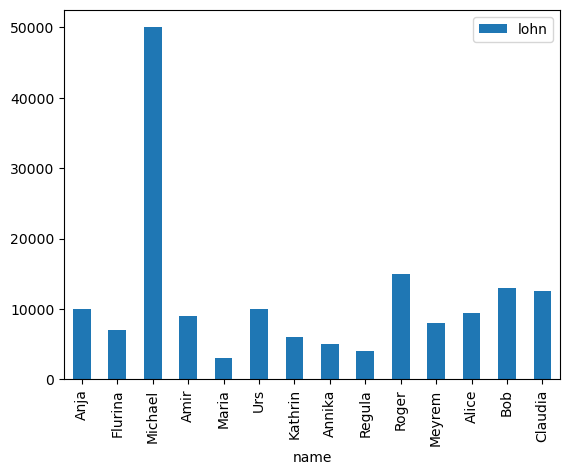

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

con = sqlite3.connect('example.db')
df = pd.read_sql_query("SELECT name, lohn from Mitarbeiter", con)

print(df.columns)

df.plot.bar(x='name', y='lohn')
plt.show()

con.close()

Der Datenrahmen kann jetzt zur Analyse der Daten genutzt werden, ohne dass weitere Abfragen in der Datenbank notwendig sind. Zum Beispiel, um folgende Frage beantworten zu können:

_"Finden Sie die weltweiten Verkaufszahlen des Videospiels mit dem Namen "Minecraft"."_

In einem ersten Schritt erzeugen wir eine Liste, welche für jede Zeile des Rahmens angibt, ob diese in der Spalte "Name" den Wert "Minecraft" stehen hat.

In [9]:
minecraft_idx = videogames_df["Name"] == "Minecraft"
minecraft_idx

0        False
1        False
2        False
3        False
4        False
         ...  
16593    False
16594    False
16595    False
16596    False
16597    False
Name: Name, Length: 16598, dtype: bool

Diese kann jetzt als Selektor genutzt werden, um die relevanten Zeilen (mit allen Spalten) herauszuholen:

In [10]:
minecraft_rows = videogames_df[minecraft_idx]
minecraft_rows

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
72,73,Minecraft,X360,2013.0,Misc,Microsoft Game Studios,5.58,2.83,0.02,0.77,9.20
168,169,Minecraft,PS3,2014.0,Misc,Sony Computer Entertainment,1.97,2.51,0.00,0.94,5.42
297,298,Minecraft,PS4,2014.0,Misc,Sony Computer Entertainment Europe,1.38,1.87,0.12,0.65,4.02
643,644,Minecraft,XOne,2014.0,Misc,Microsoft Game Studios,1.43,0.76,0.00,0.22,2.41
713,715,Minecraft,PSV,2014.0,Misc,Sony Computer Entertainment Europe,0.28,0.79,0.87,0.32,2.25
4513,4515,Minecraft,WiiU,2016.0,Misc,Microsoft Game Studios,0.18,0.09,0.14,0.03,0.43


Und zum Schluss bilden wir noch die Summe über alle Plattformen hinweg:

In [11]:
minecraft_sales_global = minecraft_rows["Global_Sales"].sum()

print(f"\nInsgesamt wurden {minecraft_sales_global} Millionen Einheiten des Spiels Minecraft verkauft.")


Insgesamt wurden 23.73 Millionen Einheiten des Spiels Minecraft verkauft.


Anstatt das Ganze Schritt für Schritt herzuleiten, lässt es sich auch in einer Zeile formulieren

In [8]:
minecraft_sales = videogames_df[videogames_df["Name"] == "Minecraft"]["Global_Sales"].sum()
minecraft_sales

np.float64(23.73)

Diese Information hätte man natürlich auch mittels eines einzigen SELECT-Befehls erhalten können. Wie würde dieser aussehen? Schreiben Sie den Python-Code dafür:

In [7]:
import sqlite3

# connect to SQLite database
conn = sqlite3.connect('example.db')
cursorObject=conn.cursor()

cursorObject.execute("""
        SELECT SUM(Global_Sales) FROM Videogame_Sales WHERE Name='Minecraft'
    """)
rows=cursorObject.fetchall()

print(f"\nInsgesamt wurden {rows[0][0]} Millionen Einheiten des Spiels Minecraft verkauft.")
    
conn.close()


Insgesamt wurden 23.73 Millionen Einheiten des Spiels Minecraft verkauft.


**Frage:** Über ein SELECT in der Datenbank zu gehen, sieht auf den ersten Blick vielleicht einfacher - zumindest einfacher verständlich - aus. Warum ist es trotzdem sinnvoll, mit Datenrahmen zu arbeiten?

***
<font size="1">_Nächster Abschnitt: [Übungsaufgabe](08_Uebung.ipynb)_</font>